# 07 - Resource and innings-progress interactions

Do explicit progress interactions improve predictions beyond state/background and both dynamic resource blocks? Compare **RBW, IB, IW and IBW** using `resource_sums_v2`. Stage 06 supplies the five-group resource comparison and shared RBW controls. This notebook uses only training and validation data.

Fit only when `RUN_STAGE=True`. Otherwise load verified results. Missing results remain pending; stale results stop without automatic fitting. See `docs/current_workflow.md` for the current candidate grid and downstream selection policy.


In [1]:
from pathlib import Path
import importlib
import json
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if not (ROOT / 'src').is_dir():
    raise FileNotFoundError('Open this notebook from the T20_Project_3.0 project or its notebooks directory.')
sys.path.insert(0, str(ROOT / 'src')) if str(ROOT / 'src') not in sys.path else None
import resource_interaction_experiments as stage
import resource_interaction_visualisation as viz
importlib.reload(stage)
importlib.reload(viz)
RUN_STAGE = False
RUN_PREFLIGHT = False
RESUME_COMPLETED_ARMS = True
SAVE_FIGURES = True
OUTPUT = ROOT / stage.REPORT_DIR
print('Project:', ROOT)
print('Design:', stage.DESIGN, '| Output:', OUTPUT)


Project: d:\T20_Project\T20_Project_3.0
Design: four_way_interactions_v1 | Output: d:\T20_Project\T20_Project_3.0\outputs\07_resource_representation_experiments\resource_sums_v2\four_way_interactions_v1


## 07.1 Four controlled representations

| Arm | Shared inputs | Explicit additions |
| --- | --- | --- |
| RBW | State/background + both remaining resource blocks | None |
| IB | Same | Four batting-resource metrics x remaining-ball fraction |
| IW | Same | Three bowling-resource metrics x remaining-ball fraction |
| IBW | Same | All seven products |

Every product uses **nominal scheduled balls remaining before the event / 120**. Keep original resource features and separate metric units. No current-player direct historical quality is added. At zero nominal remaining balls, products are zero but original resources remain. No added products does not mean that tree models cannot learn interactions.


,arm,label,added_features
0,RBW,No added interaction,0
1,IB,Batting interaction,4
2,IW,Bowling interaction,3
3,IBW,Both interactions,7


Verified experiment: 6c2f2e91b378e74e6d8007dffd3e3a13d9c5add7d1fc30e0ba81d1501caf6374
Development matches: 1293 | Events: 306871
Stage 07 candidate fits: 144 | RBW controls reused: 4
Test predictions: 0 | Downstream execution by Stage 07: False


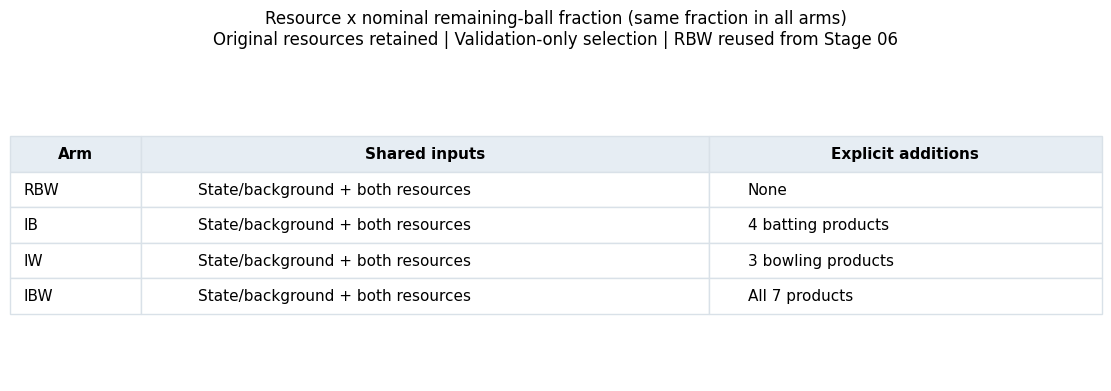

In [2]:
policy = stage.read_config(ROOT)
display(pd.DataFrame([{'arm': c, 'label': stage.LABELS[c], 'added_features': len(stage.interaction_features(c))} for c in stage.CODES]))
if RUN_PREFLIGHT:
    checks = stage.preflight(ROOT)
    display(pd.DataFrame(checks['rows']))
    print('Preflight:', checks['status'], '| Planned Stage 07 fits:', checks['expected_new_candidate_fits'])
if RUN_STAGE:
    stage.run(ROOT, resume=RESUME_COMPLETED_ARMS)
summary = None
if (OUTPUT / 'manifest.json').is_file():
    summary = stage.verified_output(ROOT)
    print('Verified experiment:', summary['experiment_id'])
    print('Development matches:', summary['development_matches'], '| Events:', summary['development_events'])
    print('Stage 07 candidate fits:', summary['new_candidate_fits'], '| RBW controls reused:', summary['reused_rbw_selected_models'])
    print('Test predictions:', summary['test_predictions'], '| Downstream execution by Stage 07:', summary['downstream_activated'])
else:
    print('Pending training. Set RUN_STAGE=True explicitly for the first run; no automatic training.')
figures = {}
if summary is not None:
    selected = pd.read_csv(OUTPUT / 'selected_models.csv')
    comparisons = pd.read_csv(OUTPUT / 'validation_comparisons.csv')
    systems = pd.read_csv(OUTPUT / 'selected_systems.csv')
    figures = viz.build_figures(ROOT)
    if SAVE_FIGURES:
        viz.save_figures(ROOT, summary, figures)
    plt.close('all')
    display(figures['design.png'])


## 07.2 Shared sample, dates and input audit

All arms inherit the frozen Stage 06 whole-match chronological split within gender, candidate grid, seed and train-only preprocessing. First-innings models omit chase-only fields. Stage 07 uses the Stage 06 split and fits on training data only, without a train+validation refit. Inspect identical event-key fingerprints across arms.


In [3]:
if summary is not None:
    audit = pd.read_csv(OUTPUT / 'input_audit.csv')
    display(audit[['track', 'split', 'arm_code', 'matches', 'events', 'event_keys_sha256']])
    groups = json.loads((OUTPUT / 'feature_groups.json').read_text(encoding='utf-8'))
    display(pd.DataFrame([{'arm': c, 'first_innings_inputs': len(stage.base.track_columns(groups[c], 1)), 'second_innings_inputs': len(stage.base.track_columns(groups[c], 2)), 'additional_columns': stage.interaction_features(c)} for c in stage.CODES]))


,track,split,arm_code,matches,events,event_keys_sha256
0,female_innings_1,train,RBW,408,50218,cbc0b8724a119da6d389e9997db3e5dbbfba72e8368c74...
1,female_innings_1,validation,RBW,88,10892,1faa5f493cdd81fbc37a3ac18b66f1a86cd74519cb1921...
2,female_innings_2,train,RBW,408,45574,b89f09129ef4155c400e11112be3c3fa1c054e719a4291...
3,female_innings_2,validation,RBW,88,10016,e8363fbce99b2027bf6efb446f50e2e37d46cca9837b5f...
4,male_innings_1,train,RBW,657,81262,e56fd2bc7760dae9b8dde94340a28b0fd99d7c6125994b...
5,male_innings_1,validation,RBW,140,17346,18d57298831fb49bfc6d4499a4d5e06480dd2ec42190b1...
6,male_innings_2,train,RBW,657,75616,7a0a7e929d307840a8fbfe9499e0474c9ed8791760ccbb...
7,male_innings_2,validation,RBW,140,15947,42448c9d188a80ad9ad74deee9d42e9fb813a80d202268...
8,female_innings_1,train,IB,408,50218,cbc0b8724a119da6d389e9997db3e5dbbfba72e8368c74...
9,female_innings_1,validation,IB,88,10892,1faa5f493cdd81fbc37a3ac18b66f1a86cd74519cb1921...


,arm,first_innings_inputs,second_innings_inputs,additional_columns
0,RBW,18,22,[]
1,IB,22,26,[progress_interaction_waiting_resource_batting...
2,IW,21,25,[progress_interaction_bowling_resource_bowling...
3,IBW,25,29,[progress_interaction_waiting_resource_batting...


## 07.3 Validation performance

Each arm selects algorithm and parameters by **validation event Log Loss** (lower is better). Accuracy, AUC, Brier and match-mean losses are supplementary. Report all tracks and arms, including unfavorable results. Small point differences alone do not establish a reliable improvement.


,track,arm_code,family,parameters,validation_event_log_loss,validation_match_log_loss,validation_brier,validation_accuracy,validation_auc
0,female_innings_1,RBW,random_forest,"{""max_depth"": 14, ""min_samples_leaf"": 50, ""n_e...",0.480220,0.478973,0.158720,0.760007,0.842703
1,female_innings_2,RBW,hist_gradient_boosting,"{""learning_rate"": 0.05, ""max_iter"": 200, ""max_...",0.289184,0.281316,0.091928,0.866813,0.948641
2,male_innings_1,RBW,logistic_regression,"{""C"": 0.01}",0.603961,0.602524,0.207722,0.678946,0.739476
3,male_innings_2,RBW,logistic_regression,"{""C"": 0.1}",0.427849,0.402728,0.142223,0.791309,0.881761
4,female_innings_1,IB,random_forest,"{""max_depth"": 14, ""min_samples_leaf"": 50, ""n_e...",0.472933,0.471453,0.155297,0.770382,0.851491
5,female_innings_2,IB,hist_gradient_boosting,"{""learning_rate"": 0.05, ""max_iter"": 200, ""max_...",0.289352,0.281610,0.091904,0.867113,0.948501
6,male_innings_1,IB,logistic_regression,"{""C"": 0.01}",0.603796,0.602336,0.207805,0.678600,0.739155
7,male_innings_2,IB,random_forest,"{""max_depth"": 8, ""min_samples_leaf"": 100, ""n_e...",0.426843,0.406818,0.141711,0.785414,0.880975
8,female_innings_1,IW,random_forest,"{""max_depth"": 14, ""min_samples_leaf"": 50, ""n_e...",0.476110,0.474637,0.157026,0.758722,0.846366
9,female_innings_2,IW,xgboost,"{""learning_rate"": 0.1, ""max_depth"": 3, ""n_esti...",0.303953,0.296069,0.098194,0.855232,0.942418


track,female_innings_1,female_innings_2,male_innings_1,male_innings_2
arm_code,,,,
RBW,0.480220,0.289184,0.603961,0.427849
IB,0.472933,0.289352,0.603796,0.426843
IW,0.476110,0.303953,0.603743,0.425819
IBW,0.477935,0.308746,0.602754,0.423766


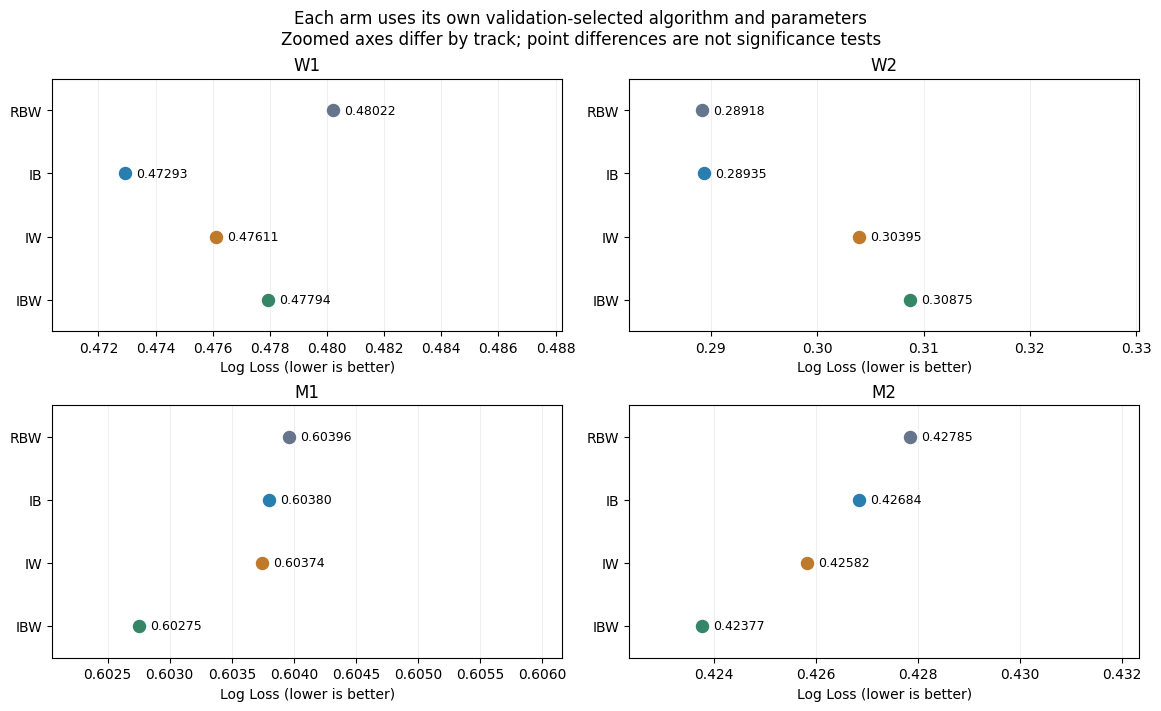

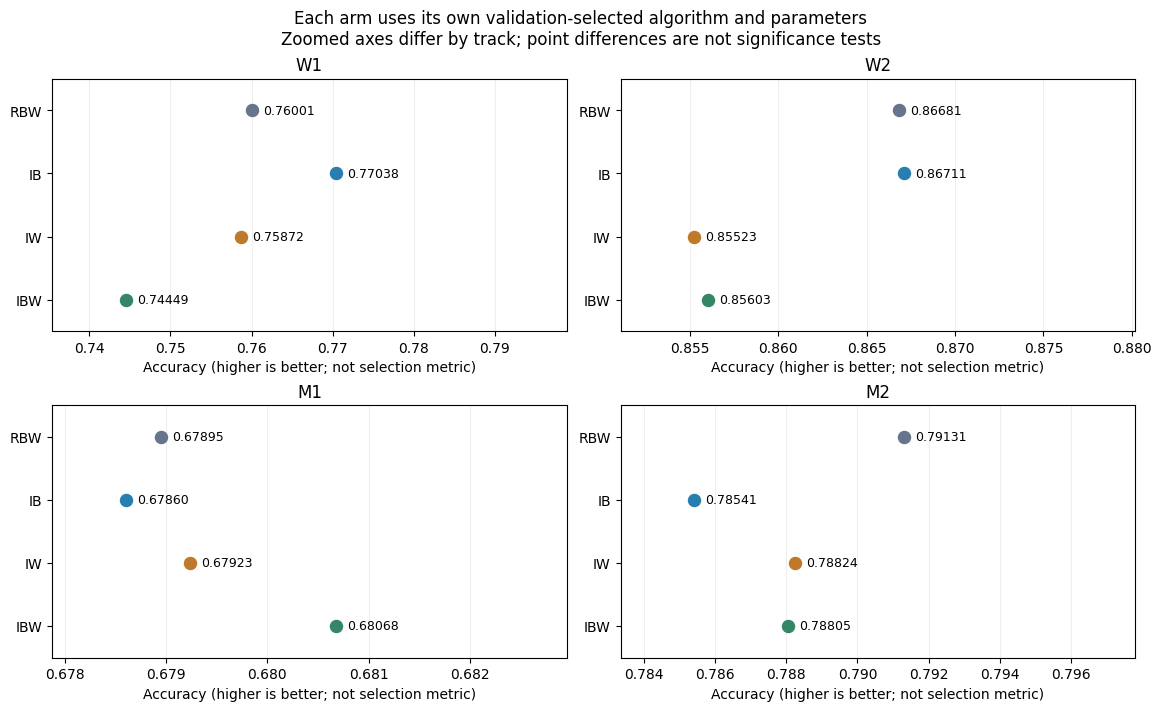

In [4]:
if summary is not None:
    display(selected[['track', 'arm_code', 'family', 'parameters', 'validation_event_log_loss', 'validation_match_log_loss', 'validation_brier', 'validation_accuracy', 'validation_auc']])
    display(selected.pivot(index='arm_code', columns='track', values='validation_event_log_loss').reindex(stage.CODES))
    display(figures['validation_log_loss.png'])
    display(figures['validation_accuracy.png'])


## 07.4 Comparisons against RBW

Positive gain means lower Log Loss than RBW. Distinguish **fixed baseline parameters**, **within-family selection**, and **selected systems**. Fixed parameters do not freeze learned coefficients, preprocessing or trees. Selected systems can change algorithms, so they compare prediction pipelines rather than an isolated causal feature effect.


,comparison_mode,track,treatment,treatment_family,reference_family,validation_log_loss_gain,validation_match_log_loss_gain,validation_brier_gain
0,fixed_baseline_parameters,female_innings_1,IB,logistic_regression,logistic_regression,-2.027946e-03,-2.016352e-03,-5.694904e-04
1,within_family_selected,female_innings_1,IB,logistic_regression,logistic_regression,-2.027946e-03,-2.016352e-03,-5.694904e-04
2,fixed_baseline_parameters,female_innings_1,IB,random_forest,random_forest,7.286888e-03,7.520151e-03,3.422536e-03
3,within_family_selected,female_innings_1,IB,random_forest,random_forest,7.286888e-03,7.520151e-03,3.422536e-03
4,fixed_baseline_parameters,female_innings_1,IB,hist_gradient_boosting,hist_gradient_boosting,-2.901540e-02,-2.899247e-02,-1.071692e-02
...,...,...,...,...,...,...,...,...
103,within_family_selected,male_innings_2,IBW,xgboost,xgboost,-8.931786e-07,-9.013761e-07,-3.781787e-07
104,selected_system,female_innings_1,IBW,xgboost,random_forest,2.284860e-03,2.968995e-03,-8.784164e-04
105,selected_system,female_innings_2,IBW,xgboost,hist_gradient_boosting,-1.956221e-02,-1.857329e-02,-6.498788e-03
106,selected_system,male_innings_1,IBW,logistic_regression,logistic_regression,1.207125e-03,1.235078e-03,3.280194e-04


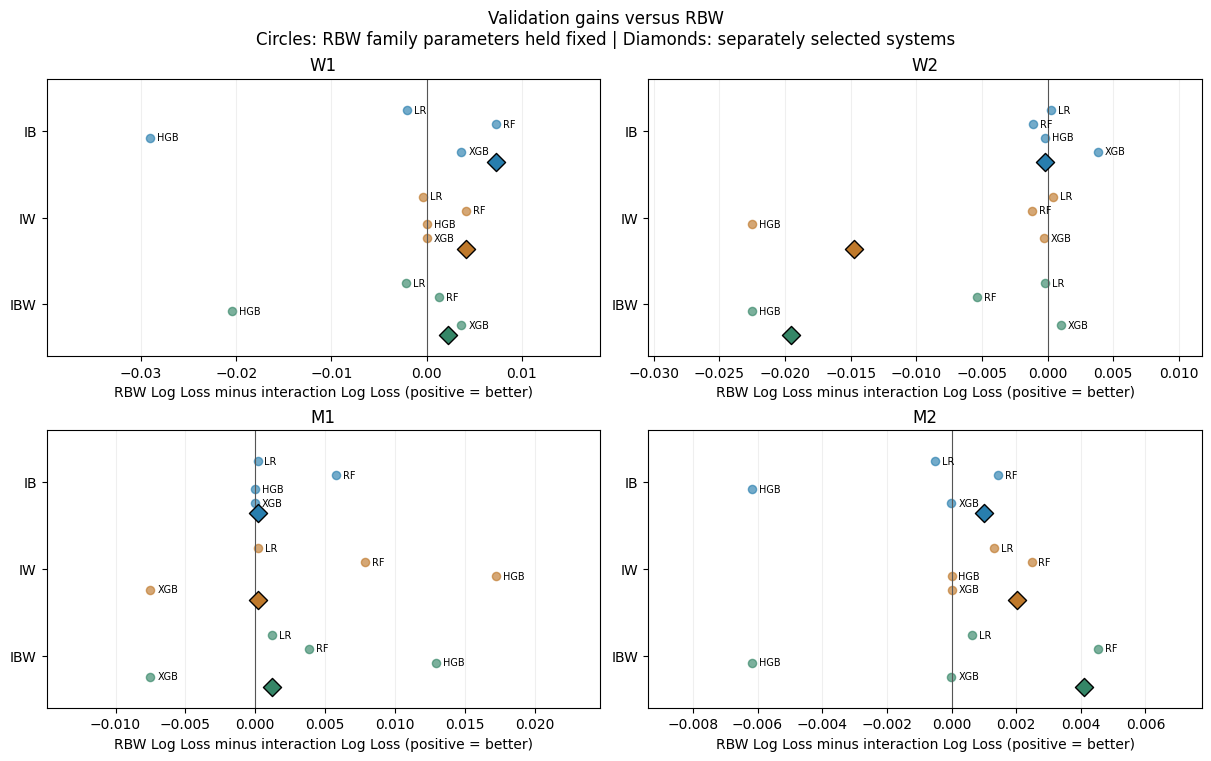

In [5]:
if summary is not None:
    display(comparisons[['comparison_mode', 'track', 'treatment', 'treatment_family', 'reference_family', 'validation_log_loss_gain', 'validation_match_log_loss_gain', 'validation_brier_gain']])
    display(figures['validation_gains.png'])


## 07.5 Phase diagnostics

These descriptive summaries reuse overall-track selected models. No separate phase-specific selection. Missing phases stay missing, not zero.


,track,arm,arm_code,phase,family,candidate,validation_event_log_loss,validation_match_log_loss,validation_brier,validation_match_brier,validation_accuracy,validation_auc,validation_events,validation_matches
0,female_innings_1,batting_progress_interactions,IB,powerplay,random_forest,1,0.536497,0.533831,0.181509,0.180309,0.717339,0.792255,3322,88
1,female_innings_1,batting_progress_interactions,IB,middle,random_forest,1,0.455694,0.455997,0.148953,0.149097,0.783374,0.866317,4884,88
2,female_innings_1,batting_progress_interactions,IB,death,random_forest,1,0.425665,0.420267,0.134415,0.132470,0.812360,0.907669,2686,88
3,female_innings_2,batting_progress_interactions,IB,powerplay,hist_gradient_boosting,0,0.420694,0.426666,0.138076,0.140222,0.784207,0.881526,3318,88
4,female_innings_2,batting_progress_interactions,IB,middle,hist_gradient_boosting,0,0.264590,0.254620,0.082472,0.079029,0.888068,0.958296,4735,88
5,female_innings_2,batting_progress_interactions,IB,death,hist_gradient_boosting,0,0.127076,0.111763,0.036612,0.032046,0.956699,0.988966,1963,79
6,male_innings_1,batting_progress_interactions,IB,powerplay,logistic_regression,0,0.633417,0.632744,0.221944,0.221646,0.637526,0.690462,5239,140
7,male_innings_1,batting_progress_interactions,IB,middle,logistic_regression,0,0.585719,0.585169,0.200791,0.200548,0.695641,0.756869,7777,140
8,male_innings_1,batting_progress_interactions,IB,death,logistic_regression,0,0.600427,0.599823,0.203294,0.202867,0.697691,0.759218,4330,138
9,male_innings_2,batting_progress_interactions,IB,powerplay,random_forest,0,0.550019,0.549309,0.186882,0.186619,0.727411,0.793194,5246,140


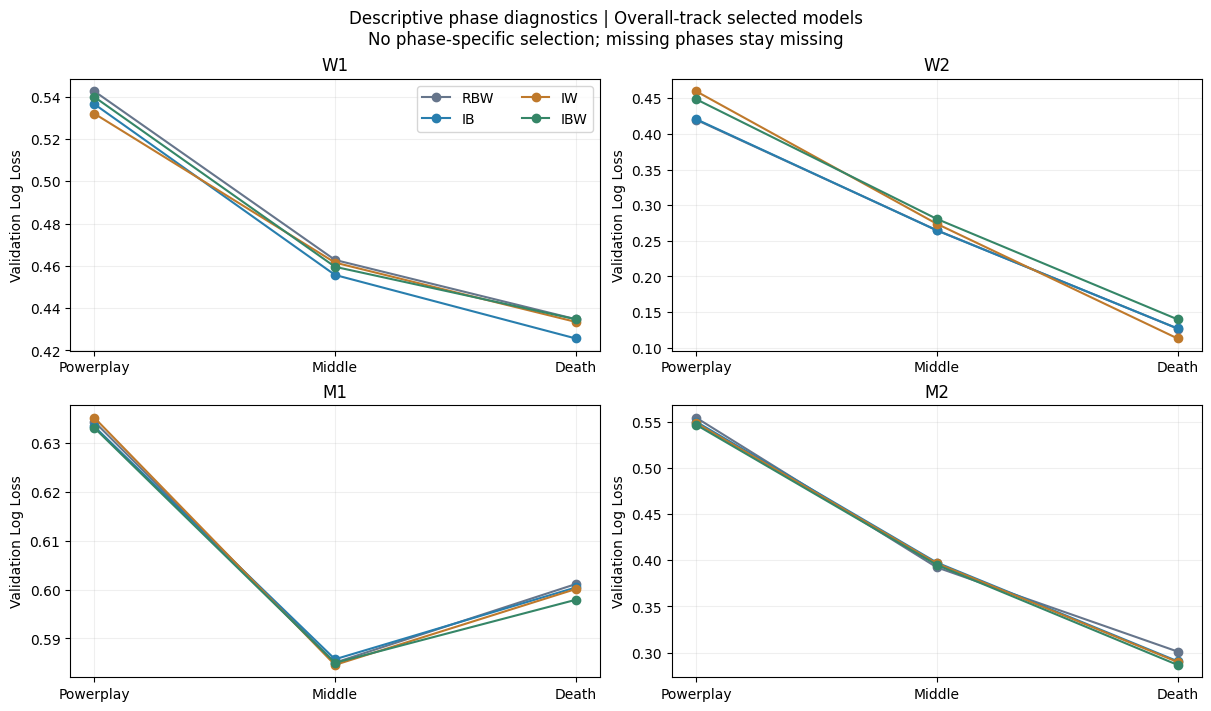

In [6]:
if summary is not None:
    display(pd.read_csv(OUTPUT / 'phase_diagnostics.csv'))
    display(figures['phase_diagnostics.png'])


## 07.6 Within-stage comparison and Stage 08 candidates

For each track, this stage reports the lowest validation event Log Loss among RBW, IB, IW and IBW. Exact ties follow that order; within-arm ties use the Stage 06 family/candidate rule. These are **within-Stage-07 winners**, not the only candidates considered downstream.

Stage 08 combines the within-group validation winners from Stage 06 and Stage 07, including the shared RBW control once. For each track, it selects the feature group, algorithm and parameters using the lowest validation event Log Loss across R0, R1, RB, RW, RBW, IB, IW and IBW. The four-way ranking here describes Stage 07 only; all its within-group winners are supplied downstream with verified paths, hashes and inputs.


In [7]:
if summary is not None:
    display(systems[['track', 'arm_code', 'family', 'parameters', 'validation_event_log_loss', 'validation_accuracy', 'model_path']])
    protocol = json.loads((OUTPUT / 'frozen_protocol.json').read_text(encoding='utf-8'))
    print('Registry:', OUTPUT / 'frozen_protocol.json')
    print('Selection handoff: all within-group winners feed Stage 08 validation-only selection across eight groups; this table summarises Stage 07.')
    for limitation in summary['limitations']:
        print('-', limitation)


,track,arm_code,family,parameters,validation_event_log_loss,validation_accuracy,model_path
0,female_innings_1,IB,random_forest,"{""max_depth"": 14, ""min_samples_leaf"": 50, ""n_e...",0.472933,0.770382,outputs/07_resource_representation_experiments...
1,female_innings_2,RBW,hist_gradient_boosting,"{""learning_rate"": 0.05, ""max_iter"": 200, ""max_...",0.289184,0.866813,outputs/06_model_training_and_comparison/model...
2,male_innings_1,IBW,logistic_regression,"{""C"": 0.01}",0.602754,0.680676,outputs/07_resource_representation_experiments...
3,male_innings_2,IBW,random_forest,"{""max_depth"": 8, ""min_samples_leaf"": 100, ""n_e...",0.423766,0.788048,outputs/07_resource_representation_experiments...


Registry: d:\T20_Project\T20_Project_3.0\outputs\07_resource_representation_experiments\resource_sums_v2\four_way_interactions_v1\frozen_protocol.json
Selection handoff: all within-group winners feed Stage 08 validation-only selection across eight groups; this table summarises Stage 07.
- Exploratory representation comparisons; independent validation is needed for stronger generalization claims.
- Validation-selected gains are subject to selection uncertainty, not independent confirmation.
- Remaining-ball fraction is nominal pre-event progress, not actual future innings length.
- No explicit products does not mean no learned interactions: tree models can learn them.
- Matched parameters do not hold learned preprocessing, coefficients or trees fixed.
- Resources remain conditioned on historical quality; these comparisons are not causal attribution.
- No test metrics, calibration fitting, NWC or automatic downstream activation in this stage.


## Interpretation and safe reuse

These are exploratory representation comparisons. Resource quality remains historical context, not causal player attribution. Independent validation is needed for stronger generalization claims. Keep the fixed metric, all group results and descriptive diagnostics together.

The experimental representations are RBW, IB, IW and IBW. Execution and verified-resume controls are documented in `docs/current_workflow.md`.
